## Problem statement
Build a CNN that predicts which clothing category appears in a small grayscale image. This notebook covers data loading, data understanding, preprocessing, model building, training, evaluation, predictions, and saving the model.



## 1. Set up the notebook



In [1]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
Available GPUs: []


## 2. Load the dataset



In [2]:
(x_train_full, y_train_full), (x_test_full, y_test_full) = tf.keras.datasets.fashion_mnist.load_data()

class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

# Use a small subset for quicker CPU training
train_size = 12000
test_size = 2000

x_train = x_train_full[:train_size].copy()
y_train = y_train_full[:train_size].copy()
x_test = x_test_full[:test_size].copy()
y_test = y_test_full[:test_size].copy()

print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)
print("Test images:", x_test.shape)
print("Test labels:", y_test.shape)

Training images: (12000, 28, 28)
Training labels: (12000,)
Test images: (2000, 28, 28)
Test labels: (2000,)


## 3. Understand the data

Each image is a 28 × 28 grid of grayscale pixel values. Each label is an integer from 0 to 9. The class-name list translates each integer into a clothing category.

In [3]:
print("Image data type:", x_train.dtype)
print("Pixel range before scaling:", x_train.min(), "to", x_train.max())
print("Number of classes:", len(np.unique(y_train)))
print("Training examples per class:")
for label, count in zip(*np.unique(y_train, return_counts=True)):
    print(class_names[label], ":", count)

Image data type: uint8
Pixel range before scaling: 0 to 255
Number of classes: 10
Training examples per class:
T-shirt/top : 1122
Trouser : 1220
Pullover : 1201
Dress : 1212
Coat : 1181
Sandal : 1204
Shirt : 1244
Sneaker : 1192
Bag : 1195
Ankle boot : 1229


## 4. Visualize sample images

Look at the images and their labels before training. This helps confirm that the data loaded correctly.

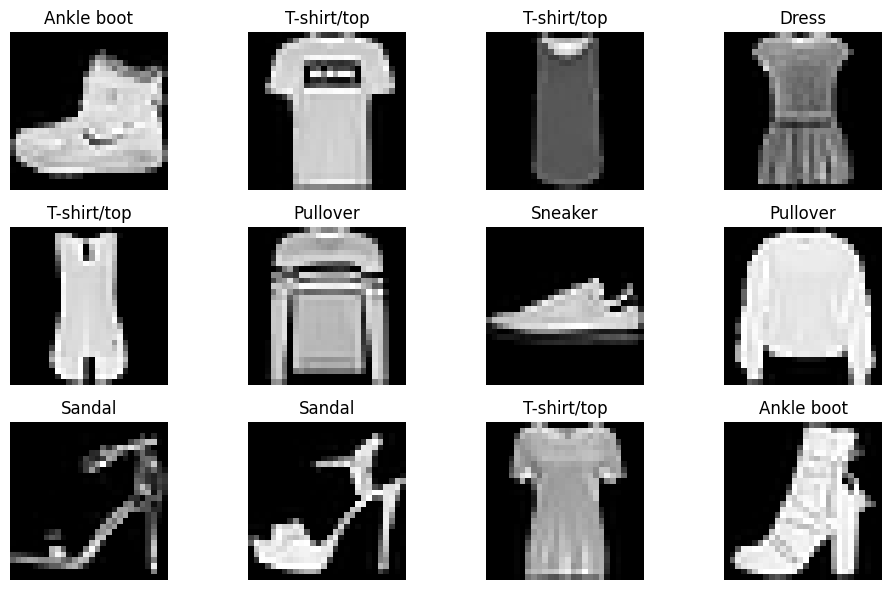

In [4]:
plt.figure(figsize=(10, 6))
for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(class_names[y_train[i]])
    plt.axis("off")
plt.tight_layout()
plt.show()

## 5. Preprocess the images

1. Scale pixel values from 0–255 to 0–1.
2. Add a channel dimension because `Conv2D` expects images in height × width × channels format.

The final image shape is 28 × 28 × 1 because these are grayscale images.

In [5]:
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

x_train = x_train[..., np.newaxis]
x_test = x_test[..., np.newaxis]

print("Preprocessed training shape:", x_train.shape)
print("Preprocessed test shape:", x_test.shape)
print("Scaled pixel range:", x_train.min(), "to", x_train.max())

Preprocessed training shape: (12000, 28, 28, 1)
Preprocessed test shape: (2000, 28, 28, 1)
Scaled pixel range: 0.0 to 1.0


## 6. Build the CNN model

- **Conv2D:** learns small visual patterns such as edges and shapes.
- **MaxPooling2D:** reduces the spatial size of the feature maps.
- **Flatten:** converts the feature maps into a one-dimensional vector.
- **Dense:** combines learned features to make a class prediction.
- **Dropout:** helps reduce overfitting by randomly dropping some activations during training.
- **Softmax output:** produces a score for each of the 10 classes.

In [6]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    tf.keras.layers.Conv2D(16, kernel_size=3, activation="relu"),
    tf.keras.layers.MaxPooling2D(pool_size=2),
    tf.keras.layers.Conv2D(32, kernel_size=3, activation="relu"),
    tf.keras.layers.MaxPooling2D(pool_size=2),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(10, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 800)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        51,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 56,714 (221.54 KB)

 Trainable params: 56,714 (221.54 KB)

 Non-trainable params: 0 (0.00 B)

## 7. Compile the model

- **Adam:** updates model weights during learning.
- **Sparse categorical cross-entropy:** suitable because labels are integer class IDs.
- **Accuracy:** reports the fraction of predictions that are correct.

In [7]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

## 8. Train the model

We hold back part of the training subset for validation. Early stopping stops training if validation loss does not improve for two epochs and restores the best weights. Training is limited to 8 epochs to keep the notebook practical on CPU.

In [8]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history = model.fit(
    x_train,
    y_train,
    epochs=8,
    batch_size=64,
    validation_split=0.2,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/8
150/150 ━━━━━━━━━━━━━━━━━━━━ 5s 23ms/step - accuracy: 0.6137 - loss: 1.0966 - val_accuracy: 0.7613 - val_loss: 0.6297
Epoch 2/8
150/150 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - accuracy: 0.7552 - loss: 0.6519 - val_accuracy: 0.7883 - val_loss: 0.5385
Epoch 3/8
150/150 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step - accuracy: 0.7875 - loss: 0.5683 - val_accuracy: 0.8075 - val_loss: 0.4943
Epoch 4/8
150/150 ━━━━━━━━━━━━━━━━━━━━ 4s 24ms/step - accuracy: 0.8089 - loss: 0.5183 - val_accuracy: 0.8254 - val_loss: 0.4646
Epoch 5/8
150/150 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - accuracy: 0.8225 - loss: 0.4848 - val_accuracy: 0.8379 - val_loss: 0.4390
Epoch 6/8
150/150 ━━━━━━━━━━━━━━━━━━━━ 5s 36ms/step - accuracy: 0.8361 - loss: 0.4492 - val_accuracy: 0.8492 - val_loss: 0.4189
Epoch 7/8
150/150 ━━━━━━━━━━━━━━━━━━━━ 7s 48ms/step - accuracy: 0.8380 - loss: 0.4353 - val_accuracy: 0.8479 - val_loss: 0.4118
Epoch 8/8
150/150 ━━━━━━━━━━━━━━━━━━━━ 6s 40ms/step - accuracy: 0.8473 - loss: 0.4101 - val_accuracy: 0.

## 9. Plot training progress

Training accuracy should generally improve. If training performance keeps improving while validation performance stops improving or gets worse, the model may be overfitting.

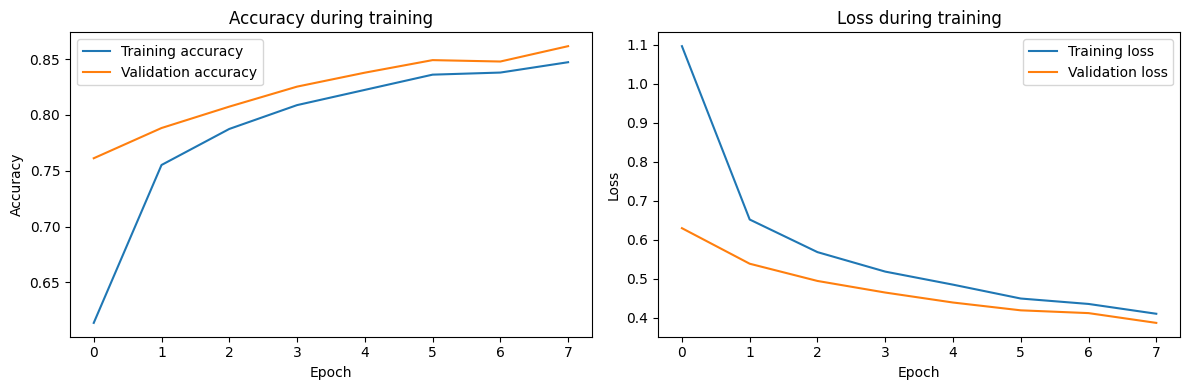

In [9]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy during training")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss during training")
plt.legend()

plt.tight_layout()
plt.show()

## 10. Evaluate on the test set

The test set was not used to update model weights. Its score gives an estimate of performance on unseen examples from this dataset.

In [10]:
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")

Test loss: 0.3945
Test accuracy: 0.8615


## 11. Make predictions

The model returns 10 scores per image. `argmax` selects the class with the highest score. The confidence shown here is the model's softmax score, not a guarantee that the prediction is correct.

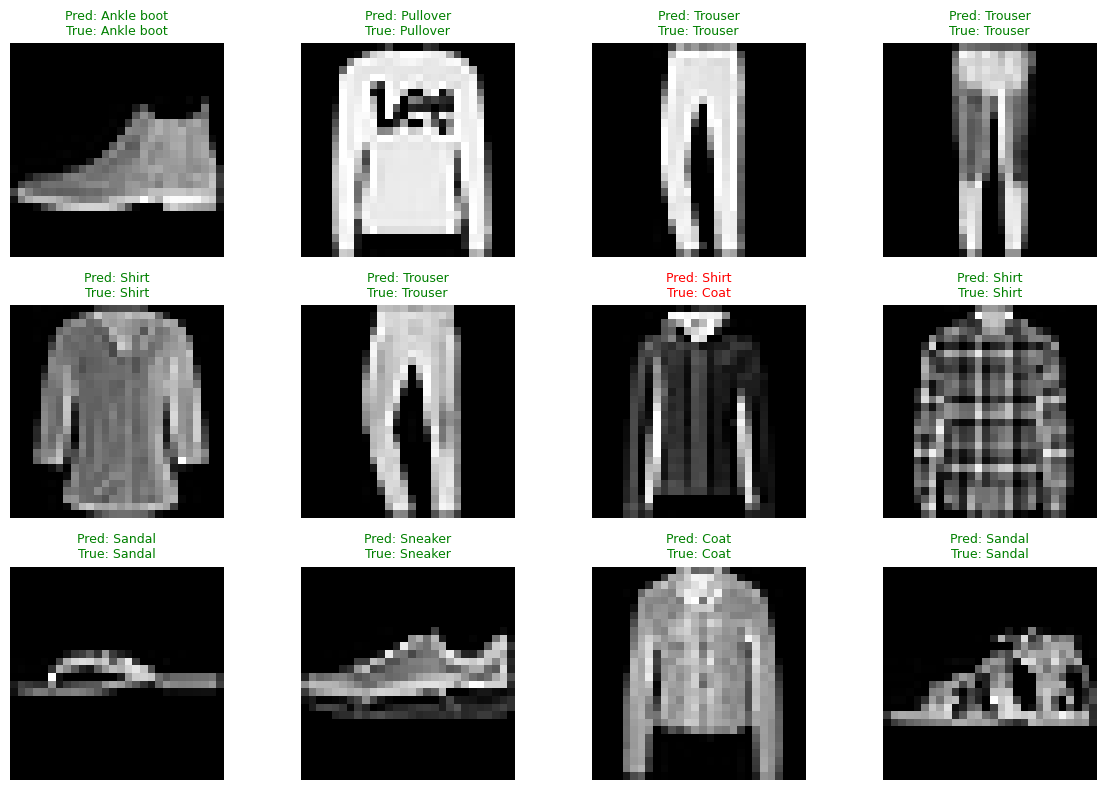

In [11]:
probabilities = model.predict(x_test[:12], verbose=0)
predicted_labels = np.argmax(probabilities, axis=1)

plt.figure(figsize=(12, 8))
for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(x_test[i].squeeze(), cmap="gray")
    correct = predicted_labels[i] == y_test[i]
    color = "green" if correct else "red"
    plt.title(
        f"Pred: {class_names[predicted_labels[i]]}\n"
        f"True: {class_names[y_test[i]]}",
        color=color,
        fontsize=9
    )
    plt.axis("off")
plt.tight_layout()
plt.show()

## 12. Classification report

Precision, recall, and F1-score give a more detailed view of how the model performs for each category. Results can vary slightly across runtime and training settings.

In [12]:
all_probabilities = model.predict(x_test, batch_size=128, verbose=0)
y_pred = np.argmax(all_probabilities, axis=1)

print(classification_report(
    y_test,
    y_pred,
    labels=list(range(10)),
    target_names=class_names,
    zero_division=0
))

              precision    recall  f1-score   support

 T-shirt/top       0.83      0.82      0.83       200
     Trouser       0.98      0.98      0.98       203
    Pullover       0.80      0.81      0.81       214
       Dress       0.90      0.84      0.87       190
        Coat       0.75      0.76      0.75       219
      Sandal       0.96      0.95      0.96       195
       Shirt       0.57      0.61      0.59       197
     Sneaker       0.92      0.96      0.94       200
         Bag       0.97      0.95      0.96       194
  Ankle boot       0.98      0.94      0.96       188

    accuracy                           0.86      2000
   macro avg       0.87      0.86      0.86      2000
weighted avg       0.86      0.86      0.86      2000



## 13. Confusion matrix

Rows represent the true categories and columns represent the predicted categories. A strong diagonal means the model correctly classified many images. Off-diagonal values show which categories the model confuses.

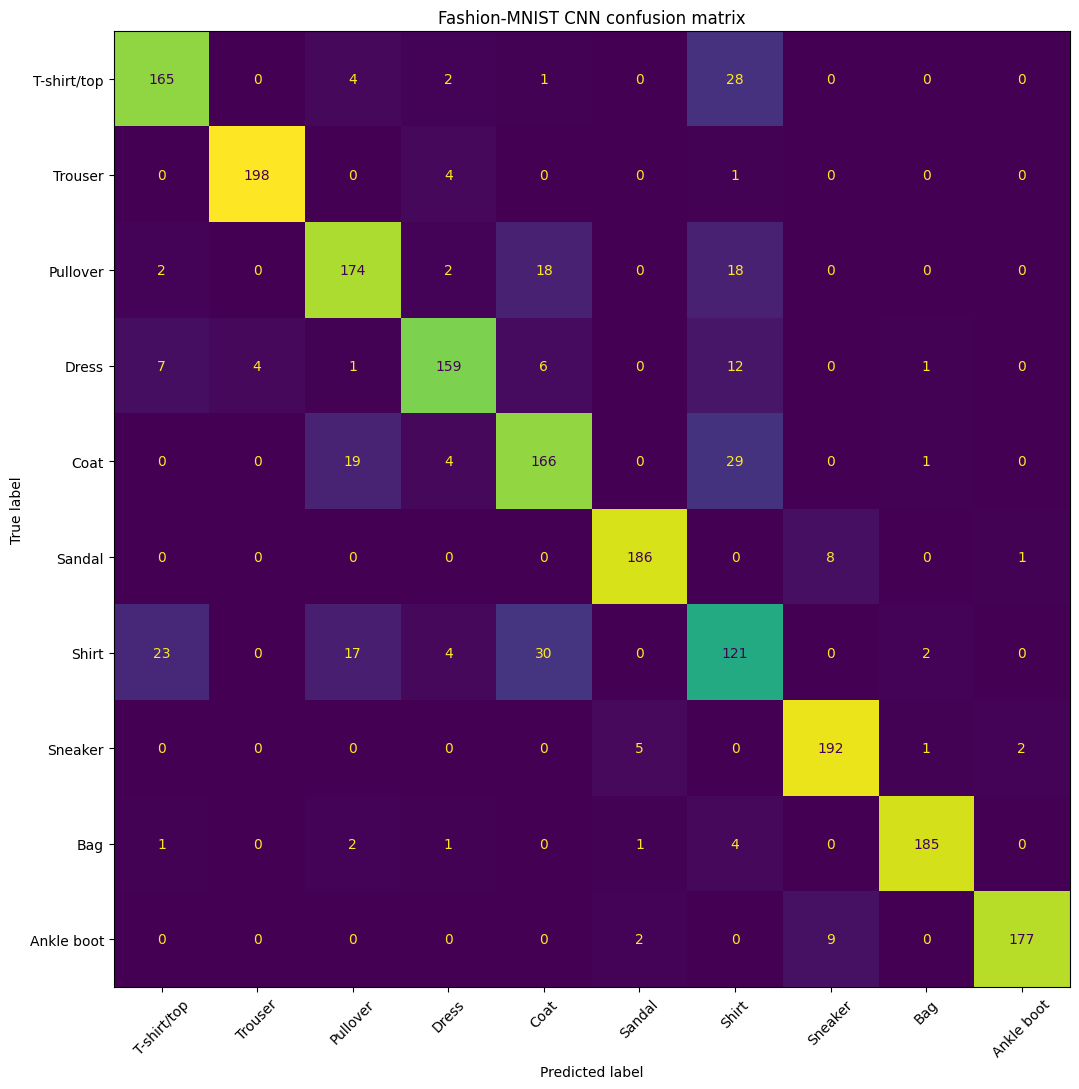

In [13]:
cm = confusion_matrix(y_test, y_pred, labels=list(range(10)))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)
fig, ax = plt.subplots(figsize=(11, 11))
display.plot(ax=ax, xticks_rotation=45, values_format="d", colorbar=False)
plt.title("Fashion-MNIST CNN confusion matrix")
plt.tight_layout()
plt.show()

## 14. Inspect one prediction

Change `sample_index` to inspect another test image. The output includes the predicted class, actual class, and top softmax score.

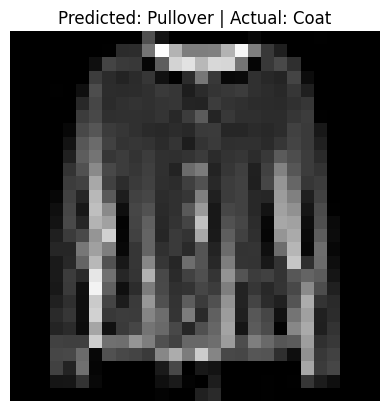

Predicted class: Pullover
Actual class: Coat
Top softmax score: 48.14%


In [14]:
sample_index = 25

sample_image = x_test[sample_index]
sample_probabilities = model.predict(sample_image[np.newaxis, ...], verbose=0)[0]
predicted_class = int(np.argmax(sample_probabilities))
actual_class = int(y_test[sample_index])

plt.imshow(sample_image.squeeze(), cmap="gray")
plt.axis("off")
plt.title(f"Predicted: {class_names[predicted_class]} | Actual: {class_names[actual_class]}")
plt.show()

print("Predicted class:", class_names[predicted_class])
print("Actual class:", class_names[actual_class])
print(f"Top softmax score: {sample_probabilities[predicted_class]:.2%}")

## 15. Save the trained model

The model is saved in Keras format. In Colab, this file is saved in the temporary runtime. Download it before closing the session if you want to keep it.

In [15]:
import os

model_path = "fashion_mnist_cnn.keras"
model.save(model_path)

print("Saved model to:", os.path.abspath(model_path))

# Download only if running in Google Colab
try:
    from google.colab import files
    files.download(model_path)
except ModuleNotFoundError:
    print("Running outside Google Colab.")
    print("The model is saved in your current folder.")

Saved model to: c:\Calibo\Phase2\DeepLearning\fashion_mnist_cnn.keras
Running outside Google Colab.
The model is saved in your current folder.
